<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/1_foundations/classical_dynamics/cm_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Classical Dynamics* — `cm_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Classical Mechanics — Interactive Visualizations
**PSE Lab, SeoulTech**

| # | Visualization | Chapter | Key Concept |
|---|---|---|---|
| 1 | Effective Potential & Kepler Orbits | Ch1 | Central force, eccentricity |
| 2 | Rotating Hoop Bifurcation | Ch2 | E-L eqn, pitchfork bifurcation |
| 3 | Double Pendulum & Lyapunov | Ch2 | Chaos, sensitivity to ICs |
| 4 | Free Symmetric Top (Poinsot) | Ch3 | Euler equations, inertia tensor |
| 5 | Heavy Top: Precession & Nutation | Ch3 | Euler angles, effective potential |
| 6 | Phase Space Flow & Separatrix | Ch4 | Hamilton equations |
| 7 | Liouville Theorem Ensemble | Ch4 | Phase volume conservation |
| 8 | Poincaré Section | Ch4 | Integrability vs chaos |

**Run:** Runtime → Run all

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.spatial import ConvexHull
import warnings; warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor':'#0d0f14','axes.facecolor':'#141720',
    'axes.edgecolor':'#2a2f45','axes.labelcolor':'#d8dde8',
    'xtick.color':'#7a8099','ytick.color':'#7a8099',
    'grid.color':'#2a2f45','text.color':'#d8dde8',
    'axes.titlecolor':'#7ec8e3','axes.titlesize':12,
    'lines.linewidth':1.8,'figure.dpi':110,
})
ACCENT='#7ec8e3'; GOLD='#f0c060'; GREEN='#6ee7b7'; RED='#f87171'
print('Packages loaded ✓')

Packages loaded ✓


## 1 · Effective Potential & Kepler Orbits (Ch1)

$V_{\rm eff}(r) = -k/r + \ell^2/2mr^2$. Orbit type depends on energy $E$: ellipse / parabola / hyperbola.

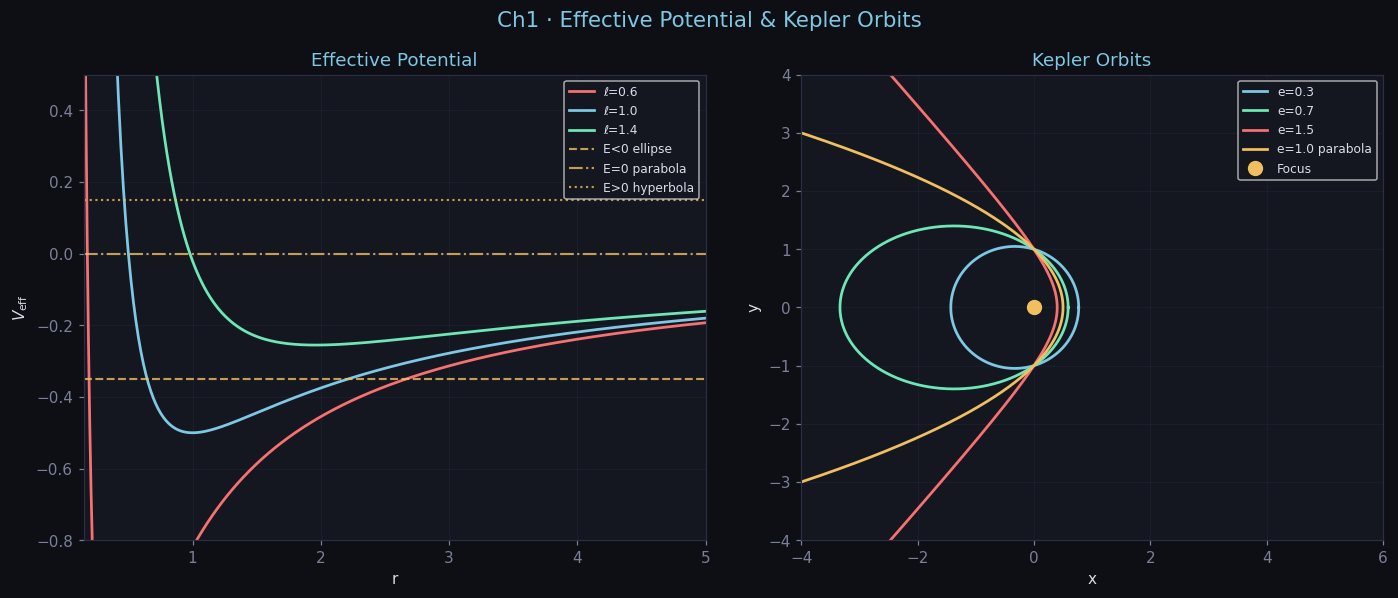

E<0: bound orbit (ellipse)  |  E>=0: unbound (parabola / hyperbola)


In [2]:
fig, axes = plt.subplots(1,2,figsize=(13,5.5))
fig.suptitle('Ch1 · Effective Potential & Kepler Orbits', color=ACCENT, fontsize=14)

# V_eff
ax=axes[0]; r=np.linspace(0.15,5,500); k=1.0
for ell,c,lab in [(0.6,RED,'ℓ=0.6'),(1.0,ACCENT,'ℓ=1.0'),(1.4,GREEN,'ℓ=1.4')]:
    ax.plot(r,-k/r+ell**2/(2*r**2),color=c,label=lab)
ell=1.0; Vref=-k/r+ell**2/(2*r**2)
for E,ls,lab in [(-0.35,'--','E<0 ellipse'),(-0.0,'-.','E=0 parabola'),(0.15,':','E>0 hyperbola')]:
    ax.axhline(E,color=GOLD,ls=ls,alpha=0.8,lw=1.4,label=lab)
ax.set_xlim(0.15,5); ax.set_ylim(-0.8,0.5)
ax.set_xlabel('r'); ax.set_ylabel('$V_{\\rm eff}$')
ax.set_title('Effective Potential'); ax.legend(fontsize=8); ax.grid(True,alpha=0.3)

# Orbit
ax2=axes[1]; phi=np.linspace(0,2*np.pi,1000)
for p,e,c,lab in [(1.0,0.3,ACCENT,'e=0.3'),(1.0,0.7,GREEN,'e=0.7'),(1.0,1.5,RED,'e=1.5')]:
    if e<1:
        ro=p/(1+e*np.cos(phi)); ax2.plot(ro*np.cos(phi),ro*np.sin(phi),color=c,label=lab)
    else:
        pm=np.arccos(-1/e)-0.05; ph2=np.linspace(-pm,pm,600)
        ro=p/(1+e*np.cos(ph2)); ax2.plot(ro*np.cos(ph2),ro*np.sin(ph2),color=c,label=lab)
ph2=np.linspace(-2.5,2.5,600); ro=1.0/(1+np.cos(ph2))
ax2.plot(ro*np.cos(ph2),ro*np.sin(ph2),color=GOLD,label='e=1.0 parabola')
ax2.plot(0,0,'o',color=GOLD,ms=9,label='Focus'); ax2.set_aspect('equal')
ax2.set_xlim(-4,6); ax2.set_ylim(-4,4)
ax2.set_xlabel('x'); ax2.set_ylabel('y')
ax2.set_title('Kepler Orbits'); ax2.legend(fontsize=8); ax2.grid(True,alpha=0.3)
plt.tight_layout(); plt.savefig('viz1_kepler.png',dpi=120,bbox_inches='tight'); plt.show()
print('E<0: bound orbit (ellipse)  |  E>=0: unbound (parabola / hyperbola)')

## 2 · Rotating Hoop — Bifurcation (Ch2)

Pitchfork bifurcation at $\Omega_c=\sqrt{g/R}$. Stability analysis via E-L equation.

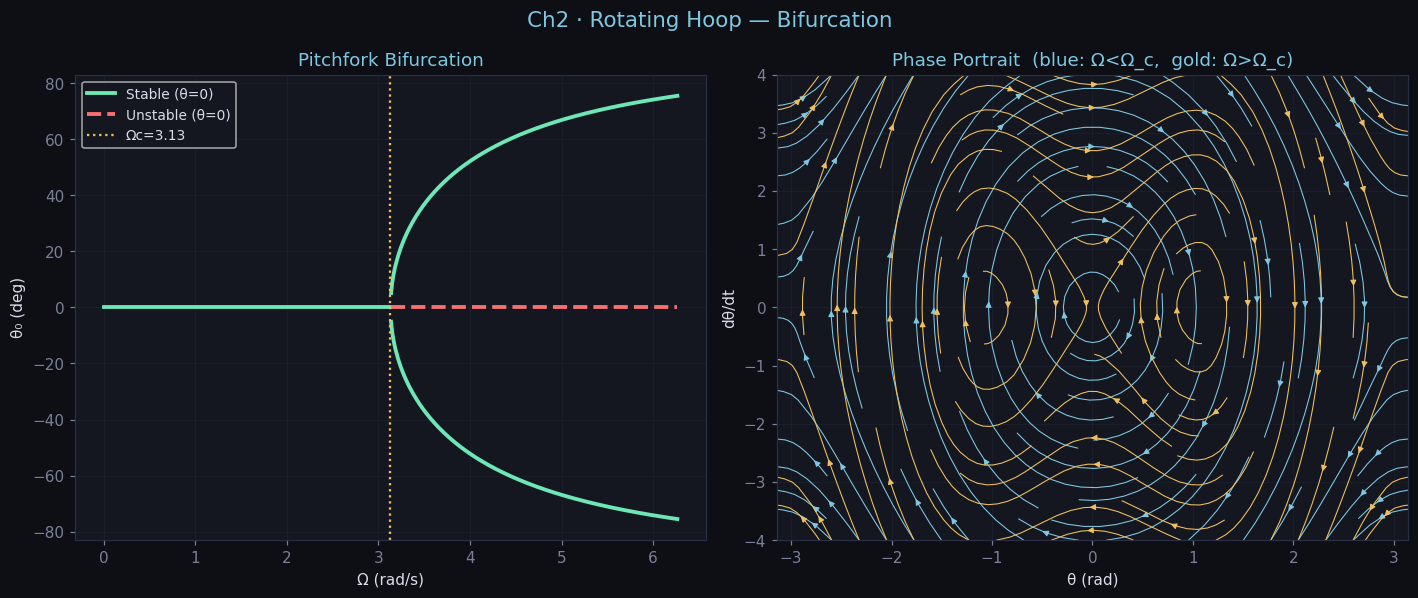

In [3]:
g=9.81; R=1.0; Oc=np.sqrt(g/R)
fig,axes=plt.subplots(1,2,figsize=(13,5.5))
fig.suptitle('Ch2 · Rotating Hoop — Bifurcation',color=ACCENT,fontsize=14)

ax=axes[0]; Om=np.linspace(0,2*Oc,500); mask=Om>Oc
ax.plot(Om[~mask],np.zeros(np.sum(~mask)),color=GREEN,lw=2.5,label='Stable (θ=0)')
ax.plot(Om[mask], np.zeros(np.sum(mask)), color=RED,  lw=2.5,ls='--',label='Unstable (θ=0)')
th_new=np.degrees(np.arccos(g/(R*Om[mask]**2)))
ax.plot(Om[mask], th_new,color=GREEN,lw=2.5)
ax.plot(Om[mask],-th_new,color=GREEN,lw=2.5)
ax.axvline(Oc,color=GOLD,ls=':',lw=1.5,label=f'Ωc={Oc:.2f}')
ax.set_xlabel('Ω (rad/s)'); ax.set_ylabel('θ₀ (deg)')
ax.set_title('Pitchfork Bifurcation'); ax.legend(fontsize=9); ax.grid(True,alpha=0.3)

# Phase portrait
ax2=axes[1]
th=np.linspace(-np.pi,np.pi,30); dth=np.linspace(-4,4,30)
TH,DTH=np.meshgrid(th,dth)
for Om_v,col,lab in [(0.7*Oc,ACCENT,'Ω=0.7Ωc'),(1.4*Oc,GOLD,'Ω=1.4Ωc')]:
    DDTH=np.sin(TH)*(R*Om_v**2*np.cos(TH)-g)/R
    spd=np.sqrt(DTH**2+DDTH**2)+1e-9
    ax2.streamplot(th,dth,DTH/spd,DDTH/spd,color=col,linewidth=0.7,density=0.8,arrowsize=0.8)
ax2.set_xlabel('θ (rad)'); ax2.set_ylabel('dθ/dt')
ax2.set_title('Phase Portrait  (blue: Ω<Ω_c,  gold: Ω>Ω_c)'); ax2.grid(True,alpha=0.3)
plt.tight_layout(); plt.savefig('viz2_hoop.png',dpi=120,bbox_inches='tight'); plt.show()

## 3 · Double Pendulum & Chaos (Ch2)

A tiny difference $\delta\theta_1(0)$ grows exponentially → Lyapunov exponent $\lambda>0$.

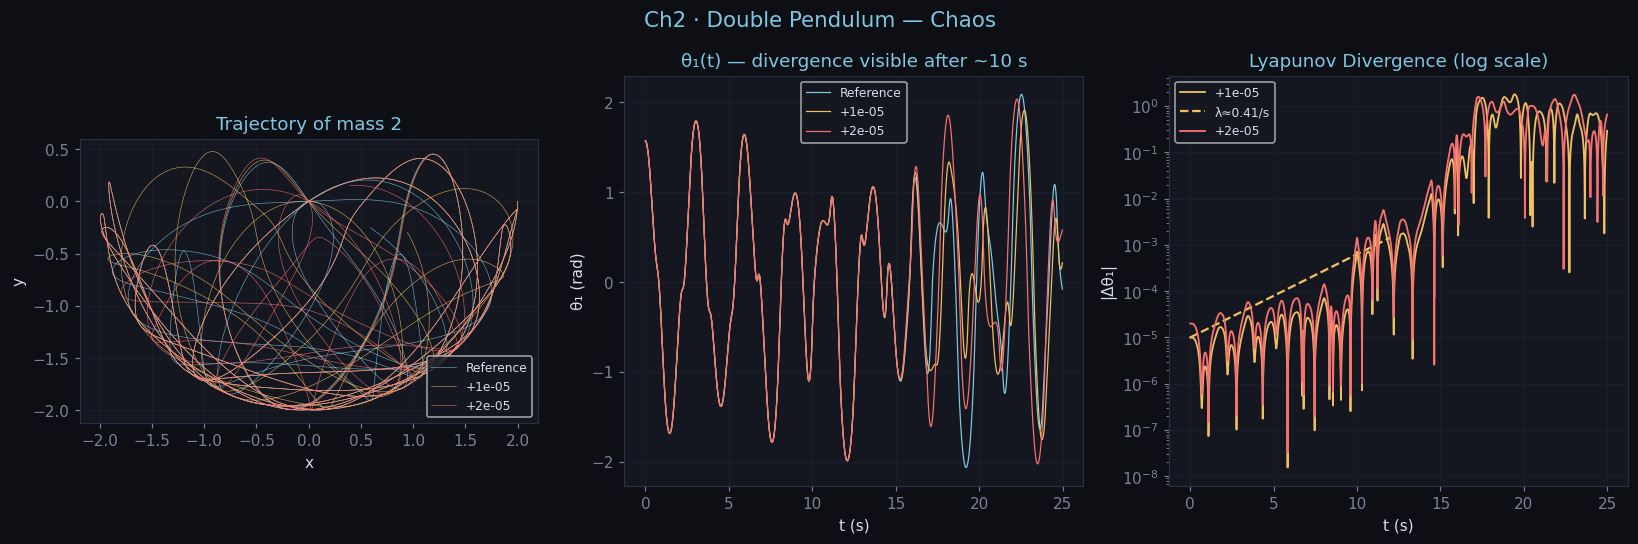

Lyapunov exponent λ ≈ 0.41 /s  →  trajectories fully diverge in τ ≈ 2.4 s


In [4]:
g_d=9.81; L1=L2=m1=m2=1.0
def dp(t,y):
    t1,w1,t2,w2=y; d=t2-t1
    D1=(m1+m2)*L1-m2*L1*np.cos(d)**2; D2=(L2/L1)*D1
    dw1=(m2*L1*w1**2*np.sin(d)*np.cos(d)+m2*g_d*np.sin(t2)*np.cos(d)
         +m2*L2*w2**2*np.sin(d)-(m1+m2)*g_d*np.sin(t1))/D1
    dw2=(-m2*L2*w2**2*np.sin(d)*np.cos(d)+(m1+m2)*g_d*np.sin(t1)*np.cos(d)
         -(m1+m2)*L1*w1**2*np.sin(d)-(m1+m2)*g_d*np.sin(t2))/D2
    return [w1,dw1,w2,dw2]

T=25; t_e=np.arange(0,T,0.01); eps=1e-5
ic0=[np.pi/2,0,np.pi/2,0]
ics=[ic0,[ic0[0]+eps,0,ic0[2],0],[ic0[0]+2*eps,0,ic0[2],0]]
sols=[solve_ivp(dp,(0,T),ic,t_eval=t_e,method='DOP853',rtol=1e-10,atol=1e-12) for ic in ics]

fig,axes=plt.subplots(1,3,figsize=(15,5))
fig.suptitle('Ch2 · Double Pendulum — Chaos',color=ACCENT,fontsize=14)
cols3=[ACCENT,GOLD,RED]; labs3=['Reference',f'+{eps:.0e}',f'+{2*eps:.0e}']

ax=axes[0]
for sol,c,lab in zip(sols,cols3,labs3):
    x2=L1*np.sin(sol.y[0])+L2*np.sin(sol.y[2])
    y2=-L1*np.cos(sol.y[0])-L2*np.cos(sol.y[2])
    ax.plot(x2,y2,color=c,lw=0.4,alpha=0.8,label=lab)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_title('Trajectory of mass 2')
ax.set_aspect('equal'); ax.grid(True,alpha=0.3); ax.legend(fontsize=8)

ax2=axes[1]
for sol,c,lab in zip(sols,cols3,labs3):
    ax2.plot(sol.t,sol.y[0],color=c,lw=0.8,label=lab)
ax2.set_xlabel('t (s)'); ax2.set_ylabel('θ₁ (rad)')
ax2.set_title('θ₁(t) — divergence visible after ~10 s'); ax2.grid(True,alpha=0.3); ax2.legend(fontsize=8)

ax3=axes[2]
lam=None
for i,(sol,c,lab) in enumerate(zip(sols[1:],cols3[1:],labs3[1:])):
    diff=np.abs(sol.y[0]-sols[0].y[0])+1e-15
    ax3.semilogy(sol.t,diff,color=c,lw=1.2,label=lab)
    if i==0:
        t_lin=sol.t[sol.t<12]; d_lin=diff[:len(t_lin)]
        v=d_lin>1e-14
        if v.sum()>5:
            lam=np.polyfit(t_lin[v],np.log(d_lin[v]),1)[0]
            ax3.semilogy(t_lin,eps*np.exp(lam*t_lin),'--',color=GOLD,lw=1.5,label=f'λ≈{lam:.2f}/s')
ax3.set_xlabel('t (s)'); ax3.set_ylabel('|Δθ₁|')
ax3.set_title('Lyapunov Divergence (log scale)'); ax3.grid(True,alpha=0.3); ax3.legend(fontsize=8)
plt.tight_layout(); plt.savefig('viz3_chaos.png',dpi=120,bbox_inches='tight'); plt.show()
if lam: print(f'Lyapunov exponent λ ≈ {lam:.2f} /s  →  trajectories fully diverge in τ ≈ {1/lam:.1f} s')

## 4 · Free Symmetric Top — Euler Equations (Ch3)

For $I_1=I_2$: $\Omega_3=\text{const}$, $\Omega_{1,2}$ precess at $\Omega_{\rm prec}=(I_3-I_1)/I_1\cdot\Omega_3$.

T change: 1.96e-05 (conserved ✓)   |ω| change: 4.39e-06 (conserved ✓)


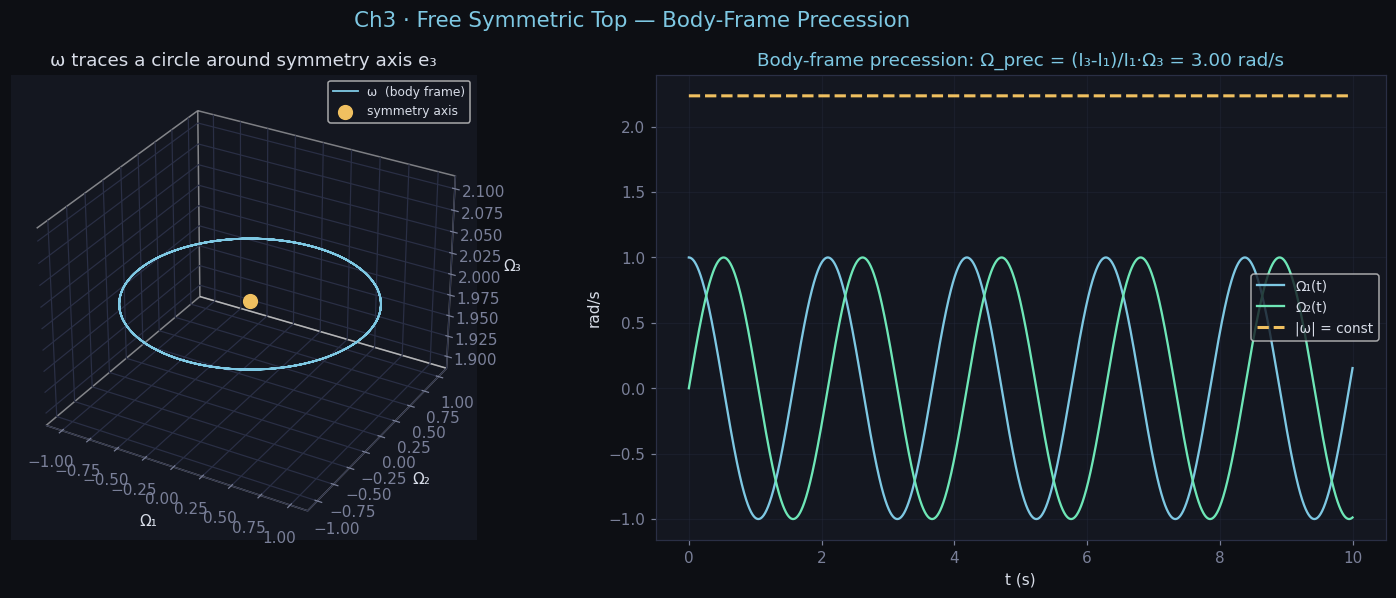

In [5]:
from mpl_toolkits.mplot3d import Axes3D
I1=2.0; I3=5.0; O3_0=2.0; Op=1.0
def euler_sym(t,y):
    O1,O2,O3=y
    return [(I1-I3)/I1*O2*O3,(I3-I1)/I1*O1*O3,0.0]
t_s=np.linspace(0,10,3000)
sol=solve_ivp(euler_sym,(0,10),[Op,0,O3_0],t_eval=t_s,rtol=1e-10)
O1s,O2s,O3s=sol.y

fig=plt.figure(figsize=(14,5.5)); fig.patch.set_facecolor('#0d0f14')
fig.suptitle('Ch3 · Free Symmetric Top — Body-Frame Precession',color=ACCENT,fontsize=14)

ax1=fig.add_subplot(121,projection='3d'); ax1.set_facecolor('#141720')
ax1.plot(O1s,O2s,O3s,color=ACCENT,lw=1.2,label='ω  (body frame)')
ax1.scatter([0],[0],[O3_0],color=GOLD,s=80,zorder=5,label='symmetry axis')
ax1.set_xlabel('Ω₁'); ax1.set_ylabel('Ω₂'); ax1.set_zlabel('Ω₃')
ax1.set_title('ω traces a circle around symmetry axis e₃',color='#d8dde8'); ax1.legend(fontsize=8)
ax1.xaxis.pane.fill=False; ax1.yaxis.pane.fill=False; ax1.zaxis.pane.fill=False

ax2=fig.add_subplot(122)
ax2.plot(t_s,O1s,color=ACCENT,lw=1.5,label='Ω₁(t)')
ax2.plot(t_s,O2s,color=GREEN, lw=1.5,label='Ω₂(t)')
ax2.plot(t_s,np.sqrt(O1s**2+O2s**2+O3s**2),color=GOLD,lw=2,ls='--',label='|ω| = const')
O_prec=(I3-I1)/I1*O3_0
ax2.set_title(f'Body-frame precession: Ω_prec = (I₃-I₁)/I₁·Ω₃ = {O_prec:.2f} rad/s')
ax2.set_xlabel('t (s)'); ax2.set_ylabel('rad/s'); ax2.grid(True,alpha=0.3); ax2.legend(fontsize=9)
T_kin=0.5*(I1*(O1s**2+O2s**2)+I3*O3s**2)
print(f'T change: {np.ptp(T_kin):.2e} (conserved ✓)   |ω| change: {np.ptp(np.sqrt(O1s**2+O2s**2+O3s**2)):.2e} (conserved ✓)')
plt.tight_layout(); plt.savefig('viz4_free_top.png',dpi=120,bbox_inches='tight'); plt.show()

## 5 · Heavy Symmetric Top — Precession & Nutation (Ch3)

$u=\cos\theta$ oscillates between two zeros of $V_{\rm eff}(u)$ → nutation. Monotone increase of $\phi$ → precession.

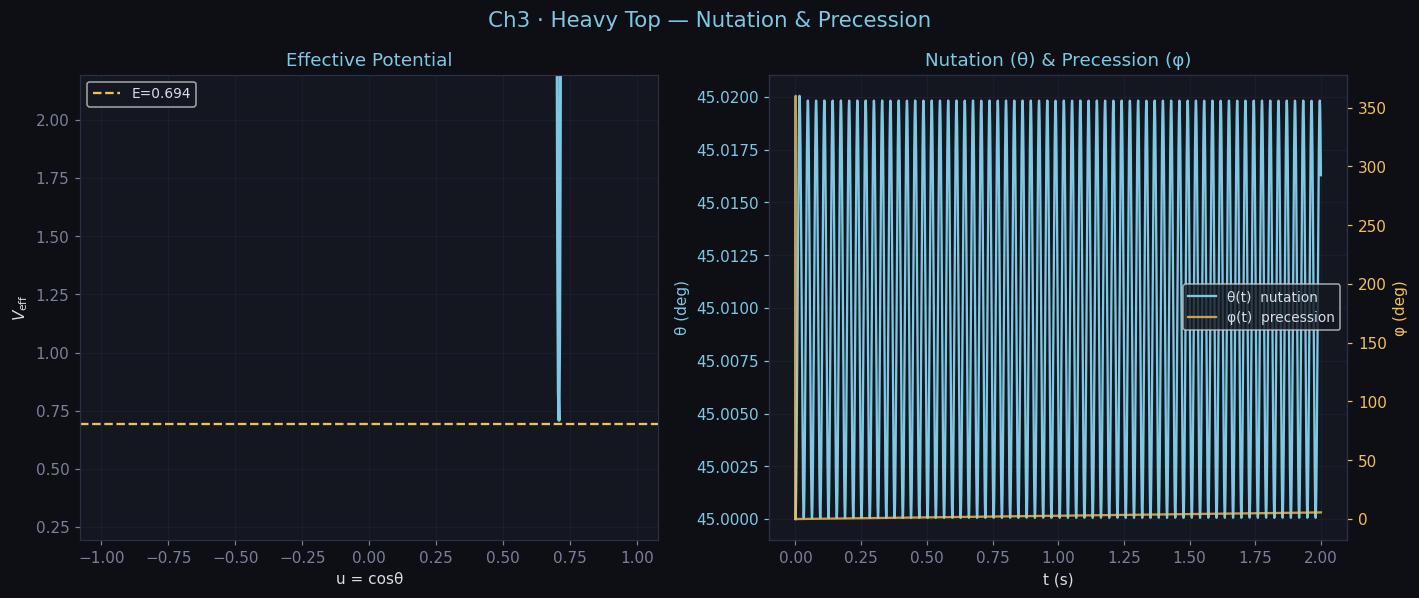

Fast spin ω₃=100.0: slow precession + small nutation confirmed


In [6]:
I1h=0.1; I3h=0.2; Mh=1.0; gh=9.81; lh=0.1; w3h=100.0; th0=np.pi/4
ppsi=I3h*w3h; pphi=ppsi*np.cos(th0)
ah=ppsi/I1h; bh=pphi/I1h; u0h=np.cos(th0)
Eh=(bh-ah*u0h)**2/(2*(1-u0h**2))+Mh*gh*lh*u0h

uu=np.linspace(-0.98,0.98,800)
Veff_h=(bh-ah*uu)**2/(2*(1-uu**2))+Mh*gh*lh*uu

fig,axes=plt.subplots(1,2,figsize=(13,5.5))
fig.suptitle('Ch3 · Heavy Top — Nutation & Precession',color=ACCENT,fontsize=14)
ax=axes[0]
ax.plot(uu,Veff_h,color=ACCENT,lw=2)
ax.axhline(Eh,color=GOLD,ls='--',lw=1.5,label=f'E={Eh:.3f}')
cr=np.where(np.diff(np.sign(Veff_h-Eh)))[0]
if len(cr)>=2:
    u1=uu[cr[0]]; u2=uu[cr[1]]
    ax.axvspan(u1,u2,alpha=0.15,color=GREEN,
               label=f'Nutation range: [{np.degrees(np.arccos(u2)):.1f}°, {np.degrees(np.arccos(u1)):.1f}°]')
ax.set_xlabel('u = cosθ'); ax.set_ylabel('$V_{\\rm eff}$')
ax.set_title('Effective Potential'); ax.set_ylim(Eh-0.5,Eh+1.5)
ax.legend(fontsize=9); ax.grid(True,alpha=0.3)

def ht_ode(t,y):
    u,ud,phi=y
    fup=(-(2*u)*(2*Eh/I1h-2*Mh*gh*lh*u/I1h)
         +(1-u**2)*(-2*Mh*gh*lh/I1h)+2*ah*(bh-ah*u))
    return [ud,fup/2,(bh-ah*u)/(1-u**2)]
th=np.linspace(0,2,5000)
sol_h=solve_ivp(ht_ode,(0,2),[u0h,1e-4,0],t_eval=th,method='DOP853',rtol=1e-9)
us,_,phis=sol_h.y; ths=np.degrees(np.arccos(np.clip(us,-1,1)))

ax2=axes[1]
ax2.plot(th,ths,color=ACCENT,lw=1.5,label='θ(t)  nutation')
ax2r=ax2.twinx()
ax2r.plot(th,np.degrees(phis)%360,color=GOLD,lw=1.5,alpha=0.8,label='φ(t)  precession')
ax2r.set_ylabel('φ (deg)',color=GOLD); ax2r.tick_params(axis='y',colors=GOLD)
ax2.set_xlabel('t (s)'); ax2.set_ylabel('θ (deg)',color=ACCENT)
ax2.tick_params(axis='y',colors=ACCENT); ax2.set_title('Nutation (θ) & Precession (φ)'); ax2.grid(True,alpha=0.3)
l1,lb1=ax2.get_legend_handles_labels(); l2,lb2=ax2r.get_legend_handles_labels()
ax2.legend(l1+l2,lb1+lb2,fontsize=9)
plt.tight_layout(); plt.savefig('viz5_heavy_top.png',dpi=120,bbox_inches='tight'); plt.show()
print(f'Fast spin ω₃={w3h}: slow precession + small nutation confirmed')

## 6 · Phase Space Flow & Separatrix (Ch4)

Simple pendulum phase space: **libration** (oscillation), **rotation**, **separatrix** (boundary at $H=mgl$).

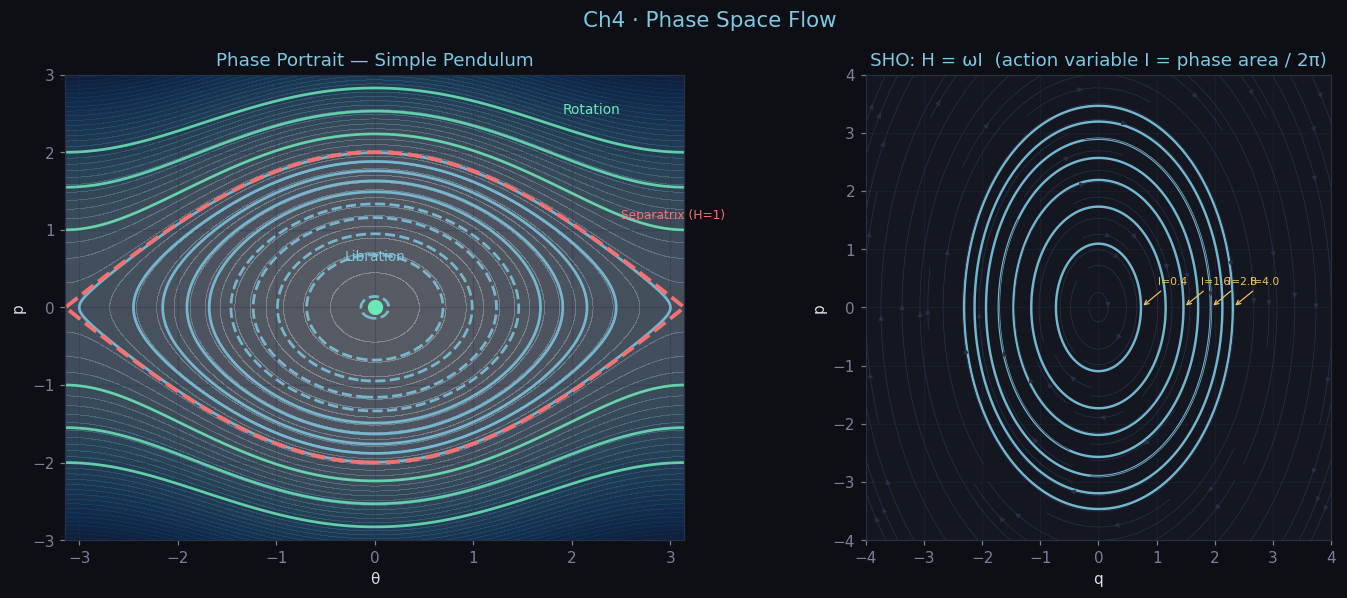

In [7]:
fig,axes=plt.subplots(1,2,figsize=(13,5.5))
fig.suptitle('Ch4 · Phase Space Flow',color=ACCENT,fontsize=14)

# Pendulum phase portrait
ax=axes[0]
tp=np.linspace(-np.pi,np.pi,400); pp=np.linspace(-3,3,300)
TP,PP=np.meshgrid(tp,pp); HP=0.5*PP**2-np.cos(TP)
ax.contourf(TP,PP,HP,levels=50,cmap='Blues',alpha=0.3)
ax.contour(TP,PP,HP,levels=np.linspace(-0.99,0.99,10),colors=ACCENT,lw=1.2,alpha=0.85)
ax.contour(TP,PP,HP,levels=[1.5,2.2,3.0],colors=GREEN,lw=1.2,alpha=0.85)
ax.contour(TP,PP,HP,levels=[1.0],colors=RED,linewidths=2.5,linestyles='--')
ax.set_xlabel('θ'); ax.set_ylabel('p'); ax.set_title('Phase Portrait — Simple Pendulum')
ax.text(0,0.6,'Libration',ha='center',color=ACCENT,fontsize=9)
ax.text(2.2,2.5,'Rotation',ha='center',color=GREEN,fontsize=9)
ax.text(2.5,1.15,'Separatrix (H=1)',color=RED,fontsize=8)
ax.plot([0],[0],'o',color=GREEN,ms=9); ax.grid(True,alpha=0.3)

# SHO action variable
ax2=axes[1]; ws=1.5
qs=np.linspace(-4,4,300); ps=np.linspace(-4,4,300)
QS,PS=np.meshgrid(qs,ps); HS=PS**2/2+0.5*ws**2*QS**2
I_vals=np.linspace(0.4,4,7)
ax2.contour(QS,PS,HS,levels=ws*I_vals,colors=ACCENT,linewidths=1.6,alpha=0.9)
dq=PS; dpe=-ws**2*QS; spd=np.sqrt(dq**2+dpe**2)+1e-9
ax2.streamplot(qs,ps,dq/spd,dpe/spd,color='#2a2f45',linewidth=0.5,density=1.0,arrowsize=0.7)
for Iv in I_vals[::2]:
    qa=np.sqrt(2*ws*Iv)/ws
    ax2.annotate(f'I={Iv:.1f}',xy=(qa,0),xytext=(qa+0.3,0.4),color=GOLD,fontsize=7,
                 arrowprops=dict(arrowstyle='->',color=GOLD,lw=0.8))
ax2.set_xlabel('q'); ax2.set_ylabel('p'); ax2.set_aspect('equal')
ax2.set_title('SHO: H = ωI  (action variable I = phase area / 2π)'); ax2.grid(True,alpha=0.3)
plt.tight_layout(); plt.savefig('viz6_phase_space.png',dpi=120,bbox_inches='tight'); plt.show()

## 7 · Liouville's Theorem (Ch4)

Under Hamiltonian flow the **phase-space volume is conserved** — the shape deforms but the area is constant.

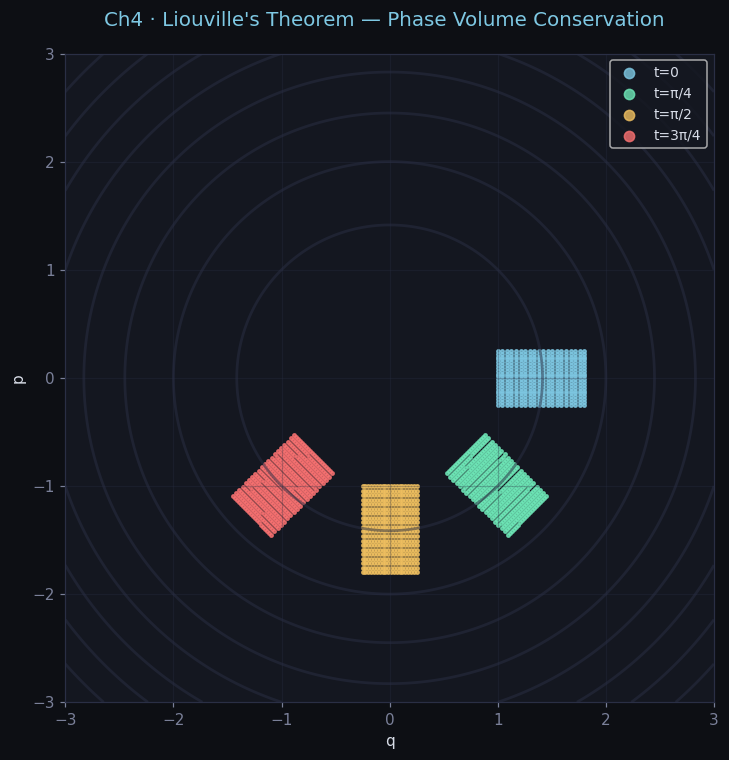

Area (Convex Hull):
  t=0: 0.40000
  t=π/4: 0.40000
  t=π/2: 0.40000
  t=3π/4: 0.40000
Max variation: 0.00%  (theory: 0%) — Liouville confirmed


In [8]:
wL=1.0
def sho_flow(t,y): return [y[1],-wL**2*y[0]]

N=20; q0s=np.linspace(1.0,1.8,N); p0s=np.linspace(-0.25,0.25,N)
Q0,P0=np.meshgrid(q0s,p0s); pts=np.column_stack([Q0.ravel(),P0.ravel()])
snaps=[0,np.pi/4,np.pi/2,3*np.pi/4]
scols=[ACCENT,GREEN,GOLD,RED]; slabs=['t=0','t=π/4','t=π/2','t=3π/4']

fig,ax=plt.subplots(figsize=(8,7))
fig.suptitle("Ch4 · Liouville's Theorem — Phase Volume Conservation",color=ACCENT,fontsize=13)

qb=np.linspace(-3,3,200); pb=np.linspace(-3,3,200)
QB,PB=np.meshgrid(qb,pb); HB=PB**2/2+QB**2/2
ax.contour(QB,PB,HB,levels=8,colors='#2a2f45',lw=0.8,alpha=0.5)

areas=[]
for tf,col,lab in zip(snaps,scols,slabs):
    ev=[]
    for pt in pts:
        if tf==0: ev.append(pt)
        else:
            s=solve_ivp(sho_flow,(0,tf),pt,rtol=1e-10); ev.append(s.y[:,-1])
    ev=np.array(ev)
    ax.scatter(ev[:,0],ev[:,1],s=5,color=col,alpha=0.8,label=lab)
    try: areas.append(ConvexHull(ev).volume)
    except: areas.append(np.nan)

ax.set_xlabel('q'); ax.set_ylabel('p'); ax.set_aspect('equal')
ax.grid(True,alpha=0.3); ax.legend(fontsize=9,markerscale=3)
plt.tight_layout(); plt.savefig('viz7_liouville.png',dpi=120,bbox_inches='tight'); plt.show()
print('Area (Convex Hull):')
for lab,ar in zip(slabs,areas): print(f'  {lab}: {ar:.5f}')
print(f'Max variation: {(max(a for a in areas if not np.isnan(a))-min(a for a in areas if not np.isnan(a)))/max(a for a in areas if not np.isnan(a))*100:.2f}%  (theory: 0%) — Liouville confirmed')

## 8 · Poincaré Section (Ch4)

Record $(\theta_1, \omega_1)$ each time $\theta_2=0$. **Low E**: points on curves = invariant tori. **High E**: scattered = chaos.

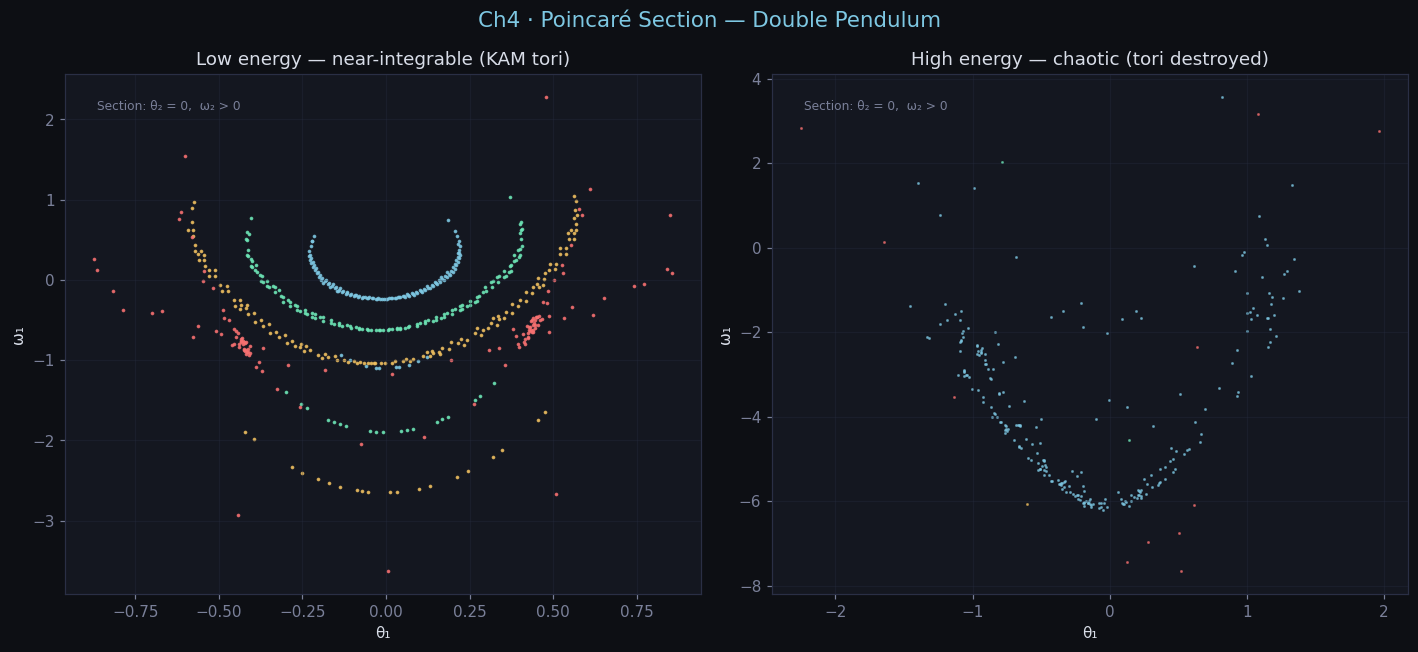

Low E: invariant tori (curves) → near-integrable
High E: tori destroyed (fills area) → chaotic


In [9]:
fig,axes=plt.subplots(1,2,figsize=(13,6))
fig.suptitle('Ch4 · Poincaré Section — Double Pendulum',color=ACCENT,fontsize=14)

def dp2(t,y):
    t1,w1,t2,w2=y; d=t2-t1; L1=L2=m1=m2=1.0; g_d=9.81
    D1=(m1+m2)*L1-m2*L1*np.cos(d)**2; D2=(L2/L1)*D1
    dw1=(m2*L1*w1**2*np.sin(d)*np.cos(d)+m2*g_d*np.sin(t2)*np.cos(d)
         +m2*L2*w2**2*np.sin(d)-(m1+m2)*g_d*np.sin(t1))/D1
    dw2=(-m2*L2*w2**2*np.sin(d)*np.cos(d)+(m1+m2)*g_d*np.sin(t1)*np.cos(d)
         -(m1+m2)*L1*w1**2*np.sin(d)-(m1+m2)*g_d*np.sin(t2))/D2
    return [w1,dw1,w2,dw2]

# Low energy
ax1=axes[0]; ax1.set_title('Low energy — near-integrable (KAM tori)',color='#d8dde8')
for th0,col in [(0.3,ACCENT),(0.5,GREEN),(0.7,GOLD),(0.9,RED)]:
    sol=solve_ivp(dp2,(0,300),[th0,0,0.1,0],method='DOP853',
                  max_step=0.02,rtol=1e-9,atol=1e-11)
    t1s,w1s,t2s,w2s=sol.y
    cr=np.where((t2s[:-1]*t2s[1:]<0)&(w2s[:-1]>0))[0]
    if len(cr)>0: ax1.scatter(t1s[cr],w1s[cr],s=2,color=col,alpha=0.8)
ax1.set_xlabel('θ₁'); ax1.set_ylabel('ω₁'); ax1.grid(True,alpha=0.3)
ax1.text(0.05,0.95,'Section: θ₂ = 0,  ω₂ > 0',transform=ax1.transAxes,color='#7a8099',fontsize=8,va='top')

# High energy
ax2=axes[1]; ax2.set_title('High energy — chaotic (tori destroyed)',color='#d8dde8')
for th0,col in [(1.5,ACCENT),(2.0,GREEN),(2.5,GOLD),(2.8,RED)]:
    sol=solve_ivp(dp2,(0,500),[th0,0,0.5,0],method='DOP853',
                  max_step=0.02,rtol=1e-9,atol=1e-11)
    t1s,w1s,t2s,w2s=sol.y
    t1s=(t1s+np.pi)%(2*np.pi)-np.pi
    cr=np.where((t2s[:-1]*t2s[1:]<0)&(w2s[:-1]>0))[0]
    if len(cr)>0: ax2.scatter(t1s[cr],w1s[cr],s=1,color=col,alpha=0.6)
ax2.set_xlabel('θ₁'); ax2.set_ylabel('ω₁'); ax2.grid(True,alpha=0.3)
ax2.text(0.05,0.95,'Section: θ₂ = 0,  ω₂ > 0',transform=ax2.transAxes,color='#7a8099',fontsize=8,va='top')
plt.tight_layout(); plt.savefig('viz8_poincare.png',dpi=120,bbox_inches='tight'); plt.show()
print('Low E: invariant tori (curves) → near-integrable')
print('High E: tori destroyed (fills area) → chaotic')

---
## Summary
| # | Visualization | Key message |
|---|---|---|
| 1 | Kepler orbits | $E<0$: ellipse; $e$ = eccentricity |
| 2 | Rotating hoop | Pitchfork bifurcation at $\Omega>\Omega_c$ |
| 3 | Double pendulum | Chaos: $\delta\theta\sim e^{\lambda t}$, $\lambda>0$ |
| 4 | Free top | $T$, $|L|$ conserved; $\omega$ traces a circle |
| 5 | Heavy top | Precession (slow $\dot\phi$) + nutation (fast $\dot\theta$) |
| 6 | Phase space | Separatrix separates libration and rotation |
| 7 | Liouville | Phase area conserved despite shape change |
| 8 | Poincaré | Low E: tori;  High E: chaos |